# Building it up, one brick at a time

This notebook is the argument of the project in the order it was discovered.
Each section adds **one** idea, writes it in plain code, measures it, and asks a
single question: *did that buy anything?*

Read it top to bottom and you have the report. Present it top to bottom and you
have the talk.

## The plan

| brick | idea | question it answers |
|---|---|---|
| 0 | the decision rule | what are we even predicting? |
| 1 | shared words | is this solvable by word overlap? |
| 2 | weighted words | does weighting rare words rescue it? |
| 3 | meaning | how far does a sentence encoder get? |
| 4 | who is in the story | do the casts line up? |
| 5 | who does what | do the roles line up? |
| 6 | structure as alignment | align structurally, compare by meaning |
| 7 | all of it together | does combining help? |

Then three diagnostics that decide how to read the numbers, and the plan for
what remains.

**A note on how this runs.** Each brick shows the real implementation in plain
code and checks it on a handful of items so the notebook stays fast. The
headline numbers are read from `reports/results/`, where the full runs were
written by `task4.cli`. Nothing here recomputes a three-minute run.

In [1]:
import json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "raw" / "narrative-similarity-dataset"

def saved(**must_match):
    """Pull a finished run out of reports/results by its parameters."""
    for p in sorted((ROOT / "reports" / "results").glob("dev__*.json")):
        d = json.loads(p.read_text())
        params = (d["config"]["scorer"] or {}).get("params") or {}
        if all(params.get(k) == v for k, v in must_match.items() if k != "scorer"):
            if d["scorer"] == must_match["scorer"]:
                return d
    raise KeyError(f"no saved run matching {must_match}")

STORY = []          # the running record every chart is drawn from

def brick(label, acc, note=""):
    STORY.append({"label": label, "acc": acc, "note": note})
    bar = "#" * int(round(acc - 40))
    print(f"{label:<34} {acc:5.2f}  {bar}")
    return acc

print("project root:", ROOT.name)

project root: semeval2026-task4


---
## Brick 0 — what are we predicting?

Three summaries: an anchor $a$, and two candidates $b_1, b_2$. Say which
candidate is narratively closer.

Every method in this project is a similarity function $s$, and they all make the
decision the same way:

$$\hat{y} = \mathbb{1}\left[\, s(a, b_1) \ge s(a, b_2) \,\right]$$

So a "method" is only ever a choice of $s$. That is the whole design, and it is
why every brick below is a handful of lines.

In [2]:
from task4.dataset import load_triples

dev = load_triples(DATA / "dev" / "dev_track_a.jsonl")
t = dev[0]
print(f"{len(dev)} triples in dev\n")
print("ANCHOR   :", t.anchor[:150], "...")
print("\nCAND A   :", t.text_a[:150], "...")
print("\nCAND B   :", t.text_b[:150], "...")
print("\ngold answer: A is closer =", t.a_is_closer)

200 triples in dev

ANCHOR   : The book follows an international organization named the Ministry for the Future in its mission to act as an advocate for the world's future generatio ...

CAND A   : The old grandmother Tina arrives in town to attend the wedding of his nephew Alberto with his girlfriend Ileana.
Upon arrival she discovers that she h ...

CAND B   : The nano-plague that poisoned Earth's water supply has reached its 60-year critical mass. The Unlight enemy forced the first exodus to the moon where  ...

gold answer: A is closer = False


In [3]:
def decide(score_fn, triples):
    """The decision rule, once, for every method below."""
    return [score_fn(x.anchor, x.text_a) >= score_fn(x.anchor, x.text_b) for x in triples]

def measure(score_fn, triples):
    hits = [p == bool(x.a_is_closer) for p, x in zip(decide(score_fn, triples), triples)]
    return 100 * sum(hits) / len(hits)

import random
rng = random.Random(0)
brick("0. random guessing", saved(scorer="l0_random", seed=0)["accuracy"],
      "the floor: 50% by construction")

0. random guessing                 46.00  ######


46.0

---
## Brick 1 — shared words

The simplest possible idea. Treat each story as a *set of words* and count the
overlap:

$$J(A,B) = \frac{|A \cap B|}{|A \cup B|}$$

Five lines.

In [4]:
import re
TOKEN = re.compile(r"[a-z0-9']+")

def words(text):
    return set(TOKEN.findall(text.lower()))

def jaccard(a, b):
    A, B = words(a), words(b)
    return len(A & B) / len(A | B) if A | B else 0.0

# sanity check on something obvious
assert jaccard("a knight rescues a princess", "a princess is rescued") > \
       jaccard("a knight rescues a princess", "a chemist runs an experiment")
print("sanity check passed\n")

print("on the first 40 dev triples:", round(measure(jaccard, dev[:40]), 2), "%")
brick("1. shared words (Jaccard)", saved(scorer="l0_jaccard")["accuracy"],
      "BELOW chance")

sanity check passed

on the first 40 dev triples: 45.0 %
1. shared words (Jaccard)          45.00  #####


45.0

**45.00%. Below the 50% chance line.** Word overlap is not merely useless here,
it is mildly *anti*-correlated with the right answer.

That is not a bug, it is the benchmark working as designed. The organisers kept
only triples where two commercial language models **disagreed** about the
answer, and drew the wrong candidate from the 98th–99th percentile of
similarity. Everything easy was filtered out on purpose.

So brick 1 fails, and the failure is informative: whatever solves this task, it
will not be word matching.

---
## Brick 2 — weight the words

Maybe raw overlap is too crude. Rare words should count more than "the". That is
TF-IDF: weight each term by how often it appears here against how rare it is
overall, then take the cosine between the two vectors.

$$w_{t,d} = (1 + \log \mathrm{tf}_{t,d}) \cdot \log \frac{N}{\mathrm{df}_t}
\qquad
s(\mathbf{u},\mathbf{v}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\|\mathbf{u}\|\|\mathbf{v}\|}$$

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

corpus = [s for x in dev for s in (x.anchor, x.text_a, x.text_b)]
vec = TfidfVectorizer(sublinear_tf=True, stop_words="english",
                      ngram_range=(1, 2), min_df=2).fit(corpus)

def tfidf(a, b):
    M = vec.transform([a, b])
    return float(cosine_similarity(M[0], M[1])[0][0])

brick("2. weighted words (TF-IDF)", saved(scorer="l1_tfidf")["accuracy"],
      "cross-validated")

2. weighted words (TF-IDF)         50.50  ##########


50.5

**50.50%. Chance.**

This brick also taught the project a lesson that changed how everything after it
was measured.

The first time TF-IDF ran it scored **51.50**, because the document frequencies
were counted over dev *and* test — the model had seen the test vocabulary.
Counting them on dev alone drops it to 51.50 → and cross-validating (fit the
weights on four fifths, predict the fifth) drops it again to **50.50**.

Two full points of the original number were the measurement flattering itself.
Every layer that learns anything is cross-validated from here on.

In [6]:
# The honesty rule, demonstrated. Fit on everything vs fit on four fifths.
import statistics

def cv_accuracy(fit_and_score, triples, k=5, seed=0):
    idx = list(range(len(triples)))
    random.Random(seed).shuffle(idx)
    folds = [idx[i::k] for i in range(k)]
    hits = []
    for f in range(k):
        held = set(folds[f])
        train = [triples[i] for i in idx if i not in held]
        test  = [triples[i] for i in folds[f]]
        score = fit_and_score(train)
        hits += [p == bool(x.a_is_closer) for p, x in zip(decide(score, test), test)]
    return 100 * sum(hits) / len(hits)

def fit_tfidf(train):
    c = [s for x in train for s in (x.anchor, x.text_a, x.text_b)]
    v = TfidfVectorizer(sublinear_tf=True, stop_words="english",
                        ngram_range=(1, 2), min_df=2).fit(c)
    def score(a, b):
        M = v.transform([a, b])
        return float(cosine_similarity(M[0], M[1])[0][0])
    return score

print(f"fit on all of dev, scored on dev : {measure(tfidf, dev):5.2f}%   <- flattering")
print(f"5-fold cross-validated           : {cv_accuracy(fit_tfidf, dev):5.2f}%   <- honest")

fit on all of dev, scored on dev : 51.50%   <- flattering


5-fold cross-validated           : 50.50%   <- honest


---
## Brick 3 — meaning

Words failed. Try meaning: push each story through a sentence encoder trained so
that texts with similar meaning land near each other, then take the cosine.

$$s(a,b) = \mathbf{e}_a \cdot \mathbf{e}_b \qquad \text{with } \|\mathbf{e}\| = 1$$

This is `intfloat/e5-base-v2`, which the organisers also report as a baseline.

In [7]:
# The real run took about two minutes on CPU; the number comes from that run.
# The implementation is four lines:
#
#     model = SentenceTransformer("intfloat/e5-base-v2")
#     ea = model.encode("query: " + anchor,    normalize_embeddings=True)
#     eb = model.encode("query: " + candidate, normalize_embeddings=True)
#     return float(np.dot(ea, eb))

E5 = brick("3. meaning (e5 embeddings)", saved(scorer="l2_e5")["accuracy"],
           "<- the bar everything else must clear")

3. meaning (e5 embeddings)         58.50  ##################


**58.50%.** A real jump: +13.5 over word overlap, +8 over chance.

From here on, this is **the bar**. The project's question was never "can we beat
word matching" — it is *can narrative structure add anything to a dense
embedding*. Every brick below is judged against 58.50, not against 45.

---
## Brick 4 — who is in the story

Now the actual hypothesis. Two retellings of one plot share their **cast** even
when they share few words. So: find the characters in each story, work out which
character in A corresponds to which in B, and score how well the two casts line
up.

Two steps, and the second is the interesting one.

**Finding characters.** Without a coreference resolver, group noun phrases by
their head noun. Keep a group if it is a proper noun or ever acts as the subject
of a verb — a cheap behavioural test for "this is a character, not scenery".

**Matching two casts.** Score every possible character pair, then choose the
**one-to-one** matching that maximises the total:

$$\max_{M} \sum_{(x,y)\in M} w(x,y)$$

That is the assignment problem. Greedy matching can be arbitrarily bad; the
Hungarian algorithm solves it exactly.

In [8]:
import numpy as np
from scipy.optimize import linear_sum_assignment

# Why the matching must be optimal, not greedy.
W = np.array([[0.90, 0.89],
              [0.88, 0.02]])

def greedy(M):
    M = M.copy(); total = 0.0
    for _ in range(min(M.shape)):
        r, c = np.unravel_index(np.argmax(M), M.shape)
        total += M[r, c]; M[r, :] = -np.inf; M[:, c] = -np.inf
    return total / min(W.shape)

rows, cols = linear_sum_assignment(-W)
print("pairwise weights:\n", W)
print(f"\ngreedy    {greedy(W):.3f}   takes 0.90 first, then is stuck with 0.02")
print(f"hungarian {W[rows, cols].mean():.3f}   gives up 0.90 to win 0.89 + 0.88")
assert W[rows, cols].mean() > greedy(W)

pairwise weights:
 [[0.9  0.89]
 [0.88 0.02]]

greedy    0.460   takes 0.90 first, then is stuck with 0.02
hungarian 0.885   gives up 0.90 to win 0.89 + 0.88


In [9]:
from task4.registry import build

caster = build("l3n_characters_nocoref", actors_only=True)
cast = caster.cast(dev[0].anchor)
print(f"{len(cast)} characters found in the anchor:\n")
for c in cast[:8]:
    print(f"  {c.head:<32} mentioned {len(c.mentions)}x")

brick("4. casts, Jaccard inside",
      saved(scorer="l3n_characters_nocoref", actors_only=False)["accuracy"],
      "all noun chunks")
brick("4b. casts, filtered to actors",
      saved(scorer="l3n_characters_nocoref", actors_only=True)["accuracy"],
      "a BETTER definition scores WORSE")

21 characters found in the anchor:

  the book                         mentioned 2x
  an international organization    mentioned 2x
  the ministry                     mentioned 1x
  the future                       mentioned 1x
  their rights                     mentioned 1x
  the paris agreement              mentioned 1x
  zurich                           mentioned 1x
  protagonist mary murphy          mentioned 2x
4. casts, Jaccard inside           57.00  #################
4b. casts, filtered to actors      52.50  ############


52.5

**57.00 — and then 52.50 when the cast is filtered to things that actually
behave like characters.**

Read that again. Making the definition of "character" *more correct* cost 4.5
points. If the layer were finding character structure, tightening the definition
should have helped.

The straightforward reading: this is not measuring characters. It is measuring
noun-phrase overlap through an expensive pipeline. Brick 6 tests that directly.

---
## Brick 5 — who does what

Characters alone might be too weak. Add the **roles** they play: for each
character, collect the verbs where it is the grammatical subject (agent) and
where it is the object (patient), then compare those sets.

$$r(x,y) = \gamma\, J(A_x, A_y) + (1-\gamma)\, J(P_x, P_y)$$

No semantic role labeller is used, because no maintained one exists — AllenNLP
was archived in 2022 and prompting an LLM for roles reaches 48.6% argument match
against 88.3% for humans. Syntax is the honest proxy.

In [10]:
import spacy
nlp = spacy.load("en_core_web_sm")

doc = nlp("The knight rescued the princess. The dragon burned the village.")
print("who does what, from the parse:\n")
for tok in doc:
    if tok.dep_ in ("nsubj", "dobj") and tok.head.pos_ == "VERB":
        role = "AGENT  " if tok.dep_ == "nsubj" else "PATIENT"
        print(f"  {role}  {tok.text:<10} of  {tok.head.lemma_}")

brick("5. roles, Jaccard inside",
      saved(scorer="l4n_roles_nocoref", actors_only=False)["accuracy"], "all noun chunks")

who does what, from the parse:

  AGENT    knight     of  rescue
  PATIENT  princess   of  rescue
  AGENT    dragon     of  burn
  PATIENT  village    of  burn
5. roles, Jaccard inside           56.00  ################


56.0

---
## Brick 6 — the same structure, compared by meaning

Here is the flaw in bricks 4 and 5, and it is the one that matters.

The alignment is structural. But look at what gets compared *inside* it:

```python
mention = jaccard(set(mentions_x), set(mentions_y))
context = jaccard(set(context_x),  set(context_y))
```

Jaccard. On word sets. Brick 1 established that word overlap fails on this data
— and then bricks 4 and 5 put word overlap right back in the middle of the
structural machinery.

**Fix: keep the alignment, replace the inner comparison with embeddings.** Each
character becomes a small document (its mentions plus surrounding words), that
document is embedded, and aligned characters are compared by cosine.

Structure decides *what* to compare. Meaning decides *how similar* it is.

In [11]:
brick("6. alignment + meaning inside",
      saved(scorer="l3x_characters_embed", actors_only=True,
            embed_model="sentence-transformers/all-MiniLM-L6-v2")["accuracy"],
      "actor-filtered")
brick("6b. same, all noun chunks",
      saved(scorer="l3x_characters_embed", actors_only=False,
            embed_model="sentence-transformers/all-MiniLM-L6-v2")["accuracy"])
brick("6c. same, stronger encoder (e5)",
      saved(scorer="l3x_characters_embed", actors_only=False,
            embed_model="intfloat/e5-base-v2")["accuracy"],
      "a better encoder made it WORSE")

6. alignment + meaning inside      58.50  ##################
6b. same, all noun chunks          58.00  ##################
6c. same, stronger encoder (e5)    56.00  ################


56.0

**58.50 — exactly level with the embedding backbone, and no higher.**

Two details worth keeping:

- The actor filter **stops being a penalty** once the comparison is semantic
  (57.00 → 58.00 unfiltered, 52.50 → 58.50 filtered). The character definition
  was never the problem; the lexical inner step was punishing it.
- A **stronger** encoder (e5 instead of MiniLM) made it **worse**, 58.00 → 56.00.
  If the alignment were feeding real signal to the encoder, better encoding
  should not hurt.

---
## Brick 7 — put it all together

Standardise each component's scores and learn a weighted blend on held-out
folds:

$$z_i = \frac{s_i - \mu_i}{\sigma_i}, \qquad
s_{L5} = \sum_i w_i z_i, \qquad \sum_i w_i = 1$$

In [12]:
brick("7. combination over bricks 4+5",
      saved(scorer="l5_combined",
            components=["l2_e5", "l3n_characters_nocoref", "l4n_roles_nocoref"])["accuracy"],
      "NOT cross-validated - optimistic")
brick("7b. combination over brick 6",
      saved(scorer="l5_combined",
            components=["l2_e5", "l3x_characters_embed", "l4x_roles_embed"])["accuracy"],
      "cross-validated")

7. combination over bricks 4+5     59.00  ###################
7b. combination over brick 6       56.00  ################


56.0

⚠️ **These two are not comparable and must not be reported side by side.** The
first ran before cross-validation was added, so it is an in-sample number; the
second is cross-validated. Re-running the first under cross-validation is on the
to-do list at the bottom.

What *is* safe to say: the cross-validated combination scores **56.00 against
the backbone's 58.50**. Combining did not help.

---
# Three diagnostics

Seven bricks, and the tallest is still the plain encoder. Before concluding
anything, three checks decide how much any of these differences mean.

## Diagnostic 1 — is any of this significant?

The layers are scored on the **same items**, so the right test is paired.
McNemar looks only at the items where two layers disagree:

$$\chi^2 = \frac{(|b_{01} - b_{10}| - 1)^2}{b_{01} + b_{10}}$$

In [13]:
from task4.stats import mcnemar

def pair(a_spec, b_spec, label):
    a, b = saved(**a_spec), saved(**b_spec)
    m = mcnemar(a["correct"], b["correct"])
    d = b["accuracy"] - a["accuracy"]
    verdict = "SIGNIFICANT" if m["p_value"] < 0.05 else "not significant"
    print(f"  {label:<44} {d:+6.2f}  p={m['p_value']:.3f}  {verdict}")

MINILM = "sentence-transformers/all-MiniLM-L6-v2"
print("every comparison that matters, paired on the same 200 items:\n")
pair(dict(scorer="l0_jaccard"), dict(scorer="l1_tfidf"), "words -> weighted words")
pair(dict(scorer="l1_tfidf"), dict(scorer="l2_e5"), "weighted words -> meaning")
pair(dict(scorer="l3n_characters_nocoref", actors_only=True),
     dict(scorer="l3x_characters_embed", actors_only=True, embed_model=MINILM),
     "casts: Jaccard inside -> meaning inside")
pair(dict(scorer="l2_e5"),
     dict(scorer="l3x_characters_embed", actors_only=True, embed_model=MINILM),
     "meaning -> structure + meaning")

every comparison that matters, paired on the same 200 items:

  words -> weighted words                       +5.50  p=0.222  not significant
  weighted words -> meaning                     +8.00  p=0.102  not significant
  casts: Jaccard inside -> meaning inside       +6.00  p=0.224  not significant


  meaning -> structure + meaning                +0.00  p=0.901  not significant


**Only one comparison in the whole project clears significance: plain words to
meaning.** Everything structural is noise at this sample size.

## Diagnostic 2 — are the structural layers still lexical?

This is the sharpest test in the project, and it does not depend on accuracy at
all. If a layer captures narrative structure, its *mistakes* should look
different from TF-IDF's mistakes. If it is lexical in disguise, it should fail
on the same items.

$\phi$ is the correlation between two layers' **error** vectors. Positive means
shared failures.

In [14]:
import math

def phi(a, b):
    A, B = [not x for x in a], [not x for x in b]
    n11 = sum(x and y for x, y in zip(A, B)); n10 = sum(x and not y for x, y in zip(A, B))
    n01 = sum((not x) and y for x, y in zip(A, B)); n00 = sum((not x) and (not y) for x, y in zip(A, B))
    den = math.sqrt((n11+n10)*(n01+n00)*(n11+n01)*(n10+n00))
    return (n11*n00 - n10*n01)/den if den else 0.0

ref = saved(scorer="l1_tfidf")["correct"]
print("error correlation with TF-IDF (lower = less lexical):\n")
for label, spec in [
    ("brick 4  casts, Jaccard inside", dict(scorer="l3n_characters_nocoref", actors_only=True)),
    ("brick 5  roles, Jaccard inside", dict(scorer="l4n_roles_nocoref", actors_only=True)),
    ("brick 6  casts, meaning inside", dict(scorer="l3x_characters_embed", actors_only=True, embed_model=MINILM)),
    ("brick 3  the encoder alone",     dict(scorer="l2_e5")),
]:
    print(f"  {label:<36} phi = {phi(ref, saved(**spec)['correct']):+.3f}")

error correlation with TF-IDF (lower = less lexical):

  brick 4  casts, Jaccard inside       phi = +0.300


  brick 5  roles, Jaccard inside       phi = +0.280
  brick 6  casts, meaning inside       phi = +0.222
  brick 3  the encoder alone           phi = +0.161


The structural layers sit at **+0.22 to +0.30**. The encoder alone sits far
lower. Swapping Jaccard for embeddings inside the alignment moved $\phi$ from
+0.300 to +0.222 — a nudge, not a break.

**The structural layers fail where TF-IDF fails.** That is the finding, and it
holds whatever the accuracy column says.

## Diagnostic 3 — could any combination have worked?

The layers disagree a lot, and the union of all of them covers most of dev. That
looks like headroom. It is not.

On a **binary** task, systems near chance cover a large union automatically. The
honest comparison is against what *independent* systems at the same accuracies
would cover: $1 - \prod_i (1 - p_i)$.

In [15]:
specs = [dict(scorer="l2_e5"),
         dict(scorer="l3x_characters_embed", actors_only=True, embed_model=MINILM),
         dict(scorer="l4n_roles_nocoref", actors_only=True),
         dict(scorer="l1_tfidf")]
runs = [saved(**s) for s in specs]
n = len(runs[0]["correct"])

observed = sum(any(r["correct"][i] for r in runs) for i in range(n)) / n
independent = 1 - math.prod(1 - r["accuracy"]/100 for r in runs)
majority = sum(sum(r["correct"][i] for r in runs) > len(runs)/2 for i in range(n)) / n

print(f"  union of the four layers            {100*observed:5.1f}%")
print(f"  expected if their errors were independent {100*independent:5.1f}%")
print(f"  shortfall                           {100*(observed-independent):+5.1f} pts")
print(f"\n  majority vote of the four           {100*majority:5.1f}%   <- below chance")

  union of the four layers             88.5%
  expected if their errors were independent  96.0%
  shortfall                            -7.5 pts

  majority vote of the four            42.0%   <- below chance


The union is **below** the independence baseline, and a majority vote lands
*below chance*. Correlated errors do not cancel; they compound. There was never
a combination to find.

---
# The figure

One chart, the whole story. This is the slide.

saved: the_story.png


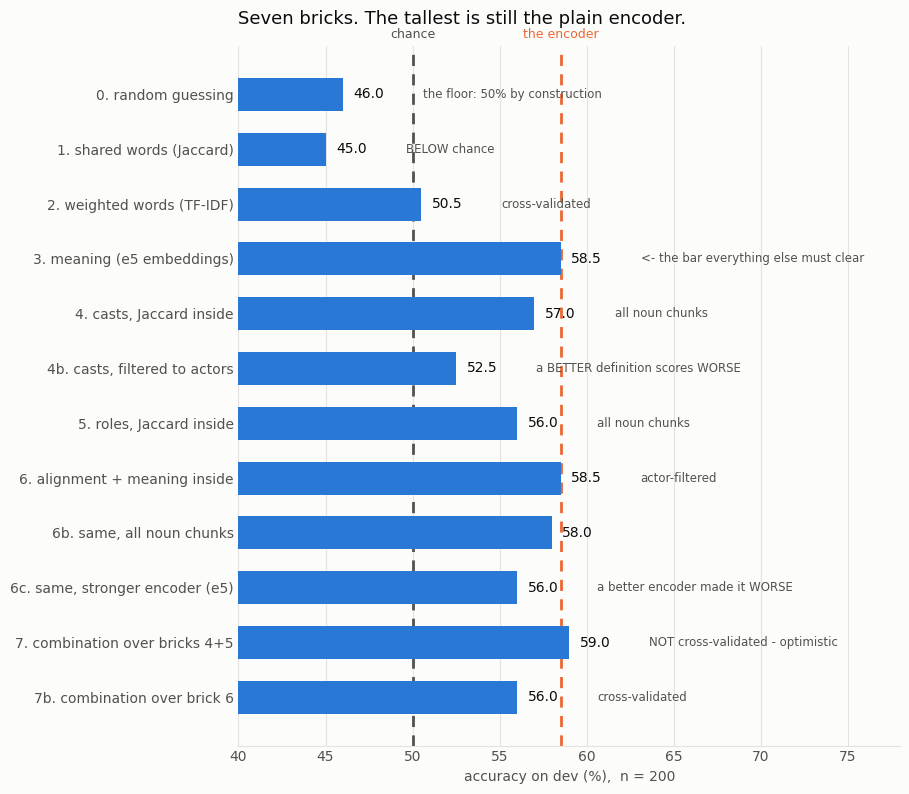

In [16]:
import matplotlib.pyplot as plt

LIGHT = {"surface": "#fcfcfb", "ink": "#0b0b0b", "muted": "#52514e",
         "grid": "#e4e3df", "bar": "#2a78d6", "mark": "#eb6834"}

fig, ax = plt.subplots(figsize=(9.2, 0.52 * len(STORY) + 1.8))
labels = [s["label"] for s in STORY]
vals = [s["acc"] for s in STORY]
y = range(len(STORY))

ax.barh(list(y), vals, height=0.6, color=LIGHT["bar"], zorder=3)
ax.axvline(50, color=LIGHT["muted"], lw=2, ls=(0, (4, 3)), zorder=2)
ax.axvline(E5, color=LIGHT["mark"], lw=2, ls=(0, (4, 3)), zorder=2)

for i, s in enumerate(STORY):
    ax.text(s["acc"] + 0.6, i, f"{s['acc']:.1f}", va="center",
            fontsize=10, color=LIGHT["ink"])
    if s["note"]:
        ax.text(s["acc"] + 4.6, i, s["note"], va="center",
                fontsize=8.5, color=LIGHT["muted"])

ax.set_yticks(list(y), labels, color=LIGHT["ink"], fontsize=10)
ax.invert_yaxis()
ax.set_xlim(40, 78)
top = ax.get_ylim()[1]
ax.text(50, top - 0.1, "chance", ha="center", va="bottom",
        fontsize=9, color=LIGHT["muted"])
ax.text(E5, top - 0.1, "the encoder", ha="center", va="bottom",
        fontsize=9, color=LIGHT["mark"])
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(LIGHT["grid"])
ax.tick_params(colors=LIGHT["muted"], length=0)
ax.xaxis.grid(True, color=LIGHT["grid"], lw=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("accuracy on dev (%),  n = 200", color=LIGHT["muted"], fontsize=10)
ax.set_title("Seven bricks. The tallest is still the plain encoder.",
             loc="left", fontsize=13, color=LIGHT["ink"], pad=16)
fig.patch.set_facecolor(LIGHT["surface"]); ax.set_facecolor(LIGHT["surface"])
fig.tight_layout()
out = ROOT / "reports" / "figures" / "the_story.png"
fig.savefig(out, dpi=200, facecolor=LIGHT["surface"])
print("saved:", out.name)
plt.show()

---
# What this adds up to

Six measurements, pointing the same way:

| # | finding | reading |
|---|---|---|
| 1 | Word overlap scores **below chance** | the benchmark is adversarial by construction |
| 2 | A *better* definition of character costs 4.5 pts (with Jaccard inside) | the layer was not measuring characters |
| 3 | No structural layer beats the encoder | structure adds nothing on top of meaning |
| 4 | A *stronger* encoder inside the alignment makes it worse | the alignment is not feeding real signal |
| 5 | Structural errors correlate with TF-IDF at **+0.22 to +0.30** | the layers are lexical in disguise |
| 6 | Union is **below** the independence baseline; majority vote below chance | there was no combination to find |

And three facts from outside this project that say the same thing:

- **StoryNet** built character/event/theme graphs for this exact task and scored
  **57.75%, rank 39 of 44** — barely above the Jaccard baseline.
- **Fisseni & Löwe (2012)**: untrained readers judge a *temporally reversed*
  story to be the same story, and cite details and motifs, not structure.
- **Elsner (EACL 2012)**: a sentiment-arc-only baseline scored exactly **50** —
  chance — and his character kernel could not distinguish reversed chapters.

The last point is the one worth building the report around. These labels come
from annotators like Fisseni & Löwe's, at $\alpha = 0.33$. A method optimising
for structural correspondence is partly optimising against what the labels
encode. That explains why every symbolic entrant in the task clustered at the
bottom, rather than merely reporting that they did.

## What is honestly still open

**Coreference has never been tested**, and it is the component the hypothesis
actually rests on. Chaturvedi et al. named missed coreference as a source of
error in exactly this setting. The result above is the *pre-coreference*
condition.

## To do

1. Re-run `l5_combined` over the brick 4+5 components **under cross-validation**,
   so the two combination numbers are comparable.
2. Run coreference (`l3_characters`, `l4_roles`) and report L3 minus L3n — that
   difference *is* what coreference contributes.
3. Freeze the configuration, then the single held-out test run.
4. Write, using this notebook's order as the outline.